In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
import random

from collections import Counter
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')

data_path= Path('/content/drive/MyDrive/DataSets/NeuroVision-AI-Deep-Learning/data/raw')
print(data_path.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
True


In [11]:
print(list(data_path.iterdir()))

[PosixPath('/content/drive/MyDrive/DataSets/NeuroVision-AI-Deep-Learning/data/raw/notumor'), PosixPath('/content/drive/MyDrive/DataSets/NeuroVision-AI-Deep-Learning/data/raw/glioma'), PosixPath('/content/drive/MyDrive/DataSets/NeuroVision-AI-Deep-Learning/data/raw/meningioma'), PosixPath('/content/drive/MyDrive/DataSets/NeuroVision-AI-Deep-Learning/data/raw/pituitary')]


In [12]:
image_extensions = {".jpg" , ".jpeg" , ".png" , ".bmp"}

for class_path in data_path.iterdir():
    if class_path.is_dir():
        images = [
            file for file in class_path.iterdir()
            if file.suffix.lower() in image_extensions
        ]
        print(f"{class_path.name} => {len(images)}, images")

notumor => 2016, images
glioma => 1621, images
meningioma => 1645, images
pituitary => 1773, images


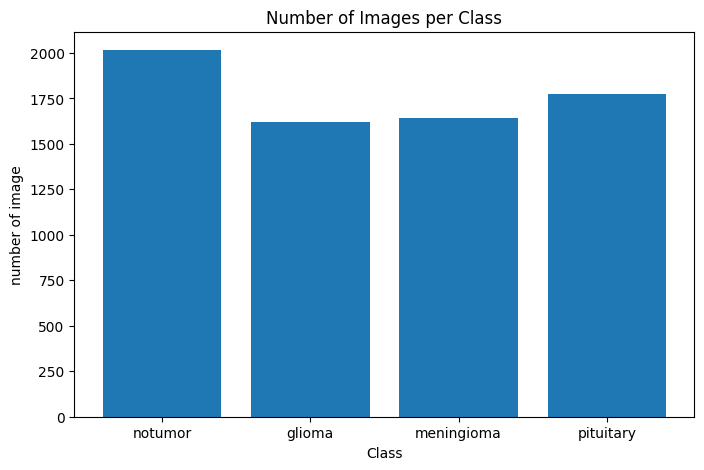

In [13]:
class_count = {}

for class_path in data_path.iterdir():
    if class_path.is_dir():
        images = [
            file for file in class_path.iterdir()
            if file.suffix.lower() in image_extensions
        ]

        class_count[class_path.name] = len(images)


plt.figure(figsize=(8 , 5))

plt.bar(class_count.keys() , class_count.values())
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("number of image")
plt.show()

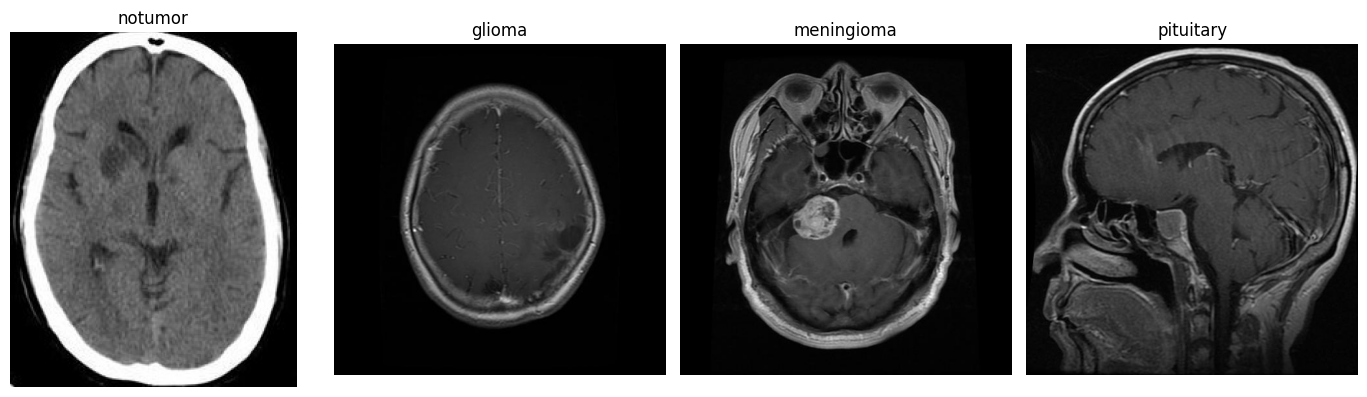

In [29]:
fix , axes = plt.subplots(1 , 4, figsize=(14 , 4))

for ax , class_name in zip(axes , class_count.keys()):
    class_path = data_path / class_name

    # display(class_path)
    # display(class_name)

    images = [
        file for file in class_path.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    # display(images)

    image_path = random.choice(images)
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image , cv2.COLOR_BGR2RGB)

    # display(image)

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [31]:
image_size = []
unreadable_images = []

for class_path in data_path.iterdir():
    if class_path.is_dir():
        for image_path in class_path.iterdir():
            if image_path.suffix.lower() in image_extensions:
                image = cv2.imread(str(image_path))

                if image is None:
                    unreadable_images.append(image_path)
                else:
                    height , width = image.shape[:2]
                    image_size.append((height , width))

print("readable images: " , len(image_size))
print("unreadable images: " , len(unreadable_images))
print("diffreant image size:" , len(set(image_size)))
print("Most common sizes:" , Counter(image_size).most_common(10))

readable images:  7055
unreadable images:  0
diffreant image size: 387
Most common sizes: [((512, 512), 4758), ((225, 225), 336), ((630, 630), 91), ((236, 236), 81), ((251, 201), 59), ((217, 232), 51), ((221, 228), 51), ((168, 300), 49), ((442, 442), 46), ((252, 200), 45)]
